In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from scipy.optimize import minimize
from scipy.stats import rankdata

In [2]:
short = pd.read_csv(
    "data/processed/short_with_regime.csv",
    index_col=0,
    parse_dates=True
)

medium = pd.read_csv(
    "data/processed/medium_with_regime.csv",
    index_col=0,
    parse_dates=True
)

long = pd.read_csv(
    "data/processed/long_with_regime.csv",
    index_col=0,
    parse_dates=True
)

short.head()

,SPY,TLT,GLD,BTC-USD,Regime
2015-02-03,0.012082,-0.017108,-0.007482,-0.021634,Normal
2015-02-04,-0.006297,0.011303,0.009490,0.012572,Normal
2015-02-05,0.007191,0.000838,0.007487,-0.036156,Normal
2015-02-06,-0.006461,-0.007030,-0.020922,0.029333,Normal
2015-02-09,-0.008716,0.007205,0.009437,-0.009858,Normal


In [3]:
TRAIN_END = "2022-12-31"

In [4]:
short_train = short.loc[:TRAIN_END].copy()
medium_train = medium.loc[:TRAIN_END].copy()
long_train = long.loc[:TRAIN_END].copy()

In [5]:
print("Short:", short_train.index.min(), "to", short_train.index.max())
print("Medium:", medium_train.index.min(), "to", medium_train.index.max())
print("Long:", long_train.index.min(), "to", long_train.index.max())

Short: 2015-02-03 00:00:00 to 2022-12-30 00:00:00
Medium: 2015-02-03 00:00:00 to 2022-12-30 00:00:00
Long: 2015-02-03 00:00:00 to 2022-12-30 00:00:00


In [6]:
short_normal = short_train[
    short_train["Regime"] == "Normal"
].drop(columns="Regime")

short_stress = short_train[
    short_train["Regime"] == "Stress"
].drop(columns="Regime")


medium_normal = medium_train[
    medium_train["Regime"] == "Normal"
].drop(columns="Regime")

medium_stress = medium_train[
    medium_train["Regime"] == "Stress"
].drop(columns="Regime")


long_normal = long_train[
    long_train["Regime"] == "Normal"
].drop(columns="Regime")

long_stress = long_train[
    long_train["Regime"] == "Stress"
].drop(columns="Regime")

In [7]:
datasets = {
    "Short_Normal": short_normal,
    "Short_Stress": short_stress,
    "Medium_Normal": medium_normal,
    "Medium_Stress": medium_stress,
    "Long_Normal": long_normal,
    "Long_Stress": long_stress
}

In [8]:
for name, df in datasets.items():
    print(name, len(df))

Short_Normal 1495
Short_Stress 498
Medium_Normal 1495
Medium_Stress 498
Long_Normal 1495
Long_Stress 498


In [9]:
pairs = [
    ("SPY", "TLT"),
    ("SPY", "GLD"),
    ("SPY", "BTC-USD"),
    ("TLT", "GLD"),
    ("TLT", "BTC-USD"),
    ("GLD", "BTC-USD")
]

In [10]:
def pseudo_observations(x):
    
    x = np.asarray(x)
    
    ranks = rankdata(x, method="average")
    
    n = len(x)
    
    u = ranks / (n + 1.0)
    
    return u

In [11]:
def prepare_pair(df, asset1, asset2):

    pair = df[
        [asset1, asset2]
    ].dropna()

    u = pseudo_observations(
        pair[asset1]
    )

    v = pseudo_observations(
        pair[asset2]
    )

    return u, v

In [12]:
u, v = prepare_pair(
    short_normal,
    "SPY",
    "BTC-USD"
)

print(u[:5])
print(v[:5])

[0.95989305 0.13836898 0.88235294 0.13235294 0.0868984 ]
[0.22794118 0.68248663 0.1236631  0.82954545 0.35427807]


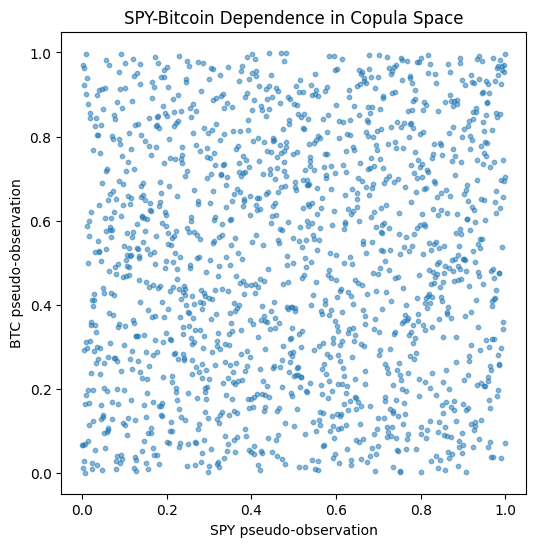

In [13]:
plt.figure(figsize=(6, 6))

plt.scatter(
    u,
    v,
    s=10,
    alpha=0.5
)

plt.xlabel("SPY pseudo-observation")
plt.ylabel("BTC pseudo-observation")

plt.title(
    "SPY-Bitcoin Dependence in Copula Space"
)

plt.show()

In [14]:
def gaussian_loglik(rho, u, v):

    rho = float(rho)

    if abs(rho) >= 0.999:
        return -np.inf

    z1 = stats.norm.ppf(u)
    z2 = stats.norm.ppf(v)

    denominator = 1 - rho**2

    log_density = (
        -0.5 * np.log(denominator)
        +
        (
            2 * rho * z1 * z2
            -
            rho**2 * (z1**2 + z2**2)
        )
        /
        (2 * denominator)
    )

    return np.sum(log_density)

In [15]:
def fit_gaussian_copula(u, v):

    def objective(params):

        rho = params[0]

        return -gaussian_loglik(
            rho,
            u,
            v
        )

    result = minimize(
        objective,
        x0=[0.2],
        bounds=[(-0.99, 0.99)],
        method="L-BFGS-B"
    )

    rho = result.x[0]

    loglik = -result.fun

    k = 1

    aic = (
        2 * k
        -
        2 * loglik
    )

    return {
        "Model": "Gaussian",
        "rho": rho,
        "nu": np.nan,
        "theta": np.nan,
        "LogLik": loglik,
        "AIC": aic
    }

In [16]:
fit_gaussian_copula(u, v)

{'Model': 'Gaussian',
 'rho': np.float64(0.0829561120103336),
 'nu': nan,
 'theta': nan,
 'LogLik': np.float64(5.0749402998123845),
 'AIC': np.float64(-8.149880599624769)}

In [17]:
def t_copula_loglik(rho, nu, u, v):

    if abs(rho) >= 0.999:
        return -np.inf

    if nu <= 2:
        return -np.inf

    x = stats.t.ppf(
        u,
        df=nu
    )

    y = stats.t.ppf(
        v,
        df=nu
    )

    observations = np.column_stack(
        [x, y]
    )

    correlation_matrix = np.array([
        [1.0, rho],
        [rho, 1.0]
    ])

    joint_logpdf = (
        stats.multivariate_t.logpdf(
            observations,
            loc=np.zeros(2),
            shape=correlation_matrix,
            df=nu
        )
    )

    marginal_logpdf = (
        stats.t.logpdf(
            x,
            df=nu
        )
        +
        stats.t.logpdf(
            y,
            df=nu
        )
    )

    log_copula_density = (
        joint_logpdf
        -
        marginal_logpdf
    )

    return np.sum(
        log_copula_density
    )

In [18]:
def fit_t_copula(u, v):

    def objective(params):

        rho = params[0]
        nu = params[1]

        return -t_copula_loglik(
            rho,
            nu,
            u,
            v
        )

    result = minimize(
        objective,
        x0=[0.2, 8.0],
        bounds=[
            (-0.99, 0.99),
            (2.05, 50.0)
        ],
        method="L-BFGS-B"
    )

    rho = result.x[0]
    nu = result.x[1]

    loglik = -result.fun

    k = 2

    aic = (
        2 * k
        -
        2 * loglik
    )

    return {
        "Model": "Student-t",
        "rho": rho,
        "nu": nu,
        "theta": np.nan,
        "LogLik": loglik,
        "AIC": aic
    }

In [19]:
fit_t_copula(u, v)

{'Model': 'Student-t',
 'rho': np.float64(0.07680794582224262),
 'nu': np.float64(12.073858690378312),
 'theta': nan,
 'LogLik': np.float64(9.744166867329838),
 'AIC': np.float64(-15.488333734659676)}

In [20]:
def clayton_loglik(theta, u, v):

    theta = float(theta)

    if theta <= 0:
        return -np.inf

    term = (
        u**(-theta)
        +
        v**(-theta)
        -
        1
    )

    if np.any(term <= 0):
        return -np.inf

    log_density = (
        np.log(1 + theta)
        +
        (-1 - theta)
        *
        (
            np.log(u)
            +
            np.log(v)
        )
        +
        (-2 - 1/theta)
        *
        np.log(term)
    )

    return np.sum(log_density)

In [21]:
def fit_clayton_copula(u, v):

    tau, _ = stats.kendalltau(
        u,
        v
    )

    # Standard Clayton requires positive dependence
    if tau <= 0:
        return None

    initial_theta = (
        2 * tau
        /
        (1 - tau)
    )

    initial_theta = max(
        initial_theta,
        0.05
    )

    def objective(params):

        theta = params[0]

        return -clayton_loglik(
            theta,
            u,
            v
        )

    result = minimize(
        objective,
        x0=[initial_theta],
        bounds=[(0.001, 30)],
        method="L-BFGS-B"
    )

    theta = result.x[0]

    loglik = -result.fun

    k = 1

    aic = (
        2 * k
        -
        2 * loglik
    )

    return {
        "Model": "Clayton",
        "rho": np.nan,
        "nu": np.nan,
        "theta": theta,
        "LogLik": loglik,
        "AIC": aic
    }

In [22]:
def gumbel_loglik(theta, u, v):

    theta = float(theta)

    if theta < 1:
        return -np.inf

    x = -np.log(u)
    y = -np.log(v)

    A = (
        x**theta
        +
        y**theta
    )

    if np.any(A <= 0):
        return -np.inf

    A_power = A**(1 / theta)

    log_C = -A_power

    log_density = (
        log_C
        -
        np.log(u)
        -
        np.log(v)
        +
        (theta - 1)
        *
        (
            np.log(x)
            +
            np.log(y)
        )
        +
        (
            2 / theta
            -
            2
        )
        *
        np.log(A)
        +
        np.log(
            1
            +
            (theta - 1)
            *
            A**(-1 / theta)
        )
    )

    return np.sum(
        log_density
    )

In [23]:
def fit_gumbel_copula(u, v):

    tau, _ = stats.kendalltau(
        u,
        v
    )

    if tau <= 0:
        return None

    initial_theta = (
        1
        /
        (1 - tau)
    )

    initial_theta = max(
        initial_theta,
        1.001
    )

    def objective(params):

        theta = params[0]

        return -gumbel_loglik(
            theta,
            u,
            v
        )

    result = minimize(
        objective,
        x0=[initial_theta],
        bounds=[(1.0001, 30)],
        method="L-BFGS-B"
    )

    theta = result.x[0]

    loglik = -result.fun

    k = 1

    aic = (
        2 * k
        -
        2 * loglik
    )

    return {
        "Model": "Gumbel",
        "rho": np.nan,
        "nu": np.nan,
        "theta": theta,
        "LogLik": loglik,
        "AIC": aic
    }

In [24]:
print(fit_gumbel_copula)

<function fit_gumbel_copula at 0x000001AD7FF97A60>


In [25]:
def fit_all_copulas(u, v):

    results = []

    gaussian = fit_gaussian_copula(
        u,
        v
    )
    results.append(gaussian)

    student_t = fit_t_copula(
        u,
        v
    )
    results.append(student_t)

    clayton = fit_clayton_copula(
        u,
        v
    )

    if clayton is not None:
        results.append(clayton)

    gumbel = fit_gumbel_copula(
        u,
        v
    )

    if gumbel is not None:
        results.append(gumbel)

    results_df = pd.DataFrame(
        results
    )

    results_df = (
        results_df
        .sort_values("AIC")
        .reset_index(drop=True)
    )

    return results_df

In [26]:
u, v = prepare_pair(
    short_normal,
    "SPY",
    "BTC-USD"
)

test_results = fit_all_copulas(
    u,
    v
)

test_results

,Model,rho,nu,theta,LogLik,AIC
0,Student-t,0.076808,12.073859,NaN,9.744167,-15.488334
1,Gumbel,NaN,NaN,1.052398,7.411848,-12.823695
2,Gaussian,0.082956,NaN,NaN,5.074940,-8.149881
3,Clayton,NaN,NaN,0.085792,4.926241,-7.852483


In [27]:
all_copula_results = []

for dataset_name, dataset in datasets.items():

    for asset1, asset2 in pairs:

        u, v = prepare_pair(
            dataset,
            asset1,
            asset2
        )

        fitted_models = fit_all_copulas(
            u,
            v
        )

        for _, row in fitted_models.iterrows():

            result = row.to_dict()

            result["Dataset"] = dataset_name

            result["Asset1"] = asset1
            result["Asset2"] = asset2

            result["Pair"] = (
                f"{asset1}-{asset2}"
            )

            result["N"] = len(u)

            all_copula_results.append(
                result
            )

In [28]:
all_copula_results = pd.DataFrame(
    all_copula_results
)

all_copula_results.head()

,Model,rho,nu,theta,LogLik,AIC,Dataset,Asset1,Asset2,Pair,N
0,Student-t,-0.225829,5.411956,NaN,57.942354,-111.884709,Short_Normal,SPY,TLT,SPY-TLT,1495
1,Gaussian,-0.222803,NaN,NaN,37.458005,-72.916010,Short_Normal,SPY,TLT,SPY-TLT,1495
2,Student-t,-0.001437,9.343418,NaN,6.740998,-9.481997,Short_Normal,SPY,GLD,SPY-GLD,1495
3,Gaussian,0.001081,NaN,NaN,0.000859,1.998282,Short_Normal,SPY,GLD,SPY-GLD,1495
4,Student-t,0.076808,12.073859,NaN,9.744167,-15.488334,Short_Normal,SPY,BTC-USD,SPY-BTC-USD,1495


In [29]:
all_copula_results = all_copula_results[
    [
        "Dataset",
        "Pair",
        "Asset1",
        "Asset2",
        "Model",
        "rho",
        "nu",
        "theta",
        "LogLik",
        "AIC",
        "N"
    ]
]

all_copula_results.head()

,Dataset,Pair,Asset1,Asset2,Model,rho,nu,theta,LogLik,AIC,N
0,Short_Normal,SPY-TLT,SPY,TLT,Student-t,-0.225829,5.411956,NaN,57.942354,-111.884709,1495
1,Short_Normal,SPY-TLT,SPY,TLT,Gaussian,-0.222803,NaN,NaN,37.458005,-72.916010,1495
2,Short_Normal,SPY-GLD,SPY,GLD,Student-t,-0.001437,9.343418,NaN,6.740998,-9.481997,1495
3,Short_Normal,SPY-GLD,SPY,GLD,Gaussian,0.001081,NaN,NaN,0.000859,1.998282,1495
4,Short_Normal,SPY-BTC-USD,SPY,BTC-USD,Student-t,0.076808,12.073859,NaN,9.744167,-15.488334,1495


In [30]:
best_models = (
    all_copula_results
    .sort_values("AIC")
    .groupby(
        ["Dataset", "Pair"],
        as_index=False
    )
    .first()
)

best_models

,Dataset,Pair,Asset1,Asset2,Model,rho,nu,theta,LogLik,AIC,N
0,Long_Normal,GLD-BTC-USD,GLD,BTC-USD,Gumbel,0.015870,35.906686,1.016794,0.715629,0.568742,1495
1,Long_Normal,SPY-BTC-USD,SPY,BTC-USD,Student-t,0.264761,6.372187,0.300692,56.064926,-108.129852,1495
2,Long_Normal,SPY-GLD,SPY,GLD,Gaussian,-0.005816,50.000000,1.000100,0.024852,1.950296,1495
3,Long_Normal,SPY-TLT,SPY,TLT,Student-t,-0.196397,5.245092,NaN,41.094437,-78.188873,1495
4,Long_Normal,TLT-BTC-USD,TLT,BTC-USD,Gaussian,-0.049516,50.000000,NaN,1.803857,-1.607713,1495
5,Long_Normal,TLT-GLD,TLT,GLD,Student-t,0.334888,6.080568,1.261081,103.413946,-202.827892,1495
6,Long_Stress,GLD-BTC-USD,GLD,BTC-USD,Student-t,0.106024,2.825159,0.368484,24.846905,-45.693811,498
7,Long_Stress,SPY-BTC-USD,SPY,BTC-USD,Clayton,0.446917,4.064550,0.817058,66.564276,-131.128551,498
8,Long_Stress,SPY-GLD,SPY,GLD,Student-t,0.190656,3.101273,1.211334,37.712688,-71.425377,498
9,Long_Stress,SPY-TLT,SPY,TLT,Gaussian,-0.025600,50.000000,NaN,0.156249,1.687502,498


In [31]:
best_model_summary = best_models[
    [
        "Dataset",
        "Pair",
        "Model",
        "rho",
        "nu",
        "theta",
        "AIC",
        "N"
    ]
]

best_model_summary

,Dataset,Pair,Model,rho,nu,theta,AIC,N
0,Long_Normal,GLD-BTC-USD,Gumbel,0.015870,35.906686,1.016794,0.568742,1495
1,Long_Normal,SPY-BTC-USD,Student-t,0.264761,6.372187,0.300692,-108.129852,1495
2,Long_Normal,SPY-GLD,Gaussian,-0.005816,50.000000,1.000100,1.950296,1495
3,Long_Normal,SPY-TLT,Student-t,-0.196397,5.245092,NaN,-78.188873,1495
4,Long_Normal,TLT-BTC-USD,Gaussian,-0.049516,50.000000,NaN,-1.607713,1495
5,Long_Normal,TLT-GLD,Student-t,0.334888,6.080568,1.261081,-202.827892,1495
6,Long_Stress,GLD-BTC-USD,Student-t,0.106024,2.825159,0.368484,-45.693811,498
7,Long_Stress,SPY-BTC-USD,Clayton,0.446917,4.064550,0.817058,-131.128551,498
8,Long_Stress,SPY-GLD,Student-t,0.190656,3.101273,1.211334,-71.425377,498
9,Long_Stress,SPY-TLT,Gaussian,-0.025600,50.000000,NaN,1.687502,498


In [32]:
best_model_summary[
    "Model"
].value_counts()

Model
Student-t    22
Gaussian      8
Gumbel        4
Clayton       2
Name: count, dtype: int64

In [33]:
def copula_tail_dependence(
    model,
    rho=np.nan,
    nu=np.nan,
    theta=np.nan
):

    if model == "Gaussian":

        lambda_L = 0.0
        lambda_U = 0.0


    elif model == "Student-t":

        value = -np.sqrt(
            ((nu + 1) * (1 - rho))
            /
            (1 + rho)
        )

        lambda_t = (
            2
            *
            stats.t.cdf(
                value,
                df=nu + 1
            )
        )

        lambda_L = lambda_t
        lambda_U = lambda_t


    elif model == "Clayton":

        lambda_L = (
            2 ** (-1 / theta)
        )

        lambda_U = 0.0


    elif model == "Gumbel":

        lambda_L = 0.0

        lambda_U = (
            2
            -
            2 ** (1 / theta)
        )


    else:

        lambda_L = np.nan
        lambda_U = np.nan

    return lambda_L, lambda_U

In [34]:
tail_dependence_results = []

for _, row in best_model_summary.iterrows():

    lambda_L, lambda_U = copula_tail_dependence(
        model=row["Model"],
        rho=row["rho"],
        nu=row["nu"],
        theta=row["theta"]
    )

    result = row.to_dict()

    result["Lambda_L"] = lambda_L
    result["Lambda_U"] = lambda_U

    tail_dependence_results.append(
        result
    )

In [35]:
copula_tail_table = pd.DataFrame(
    tail_dependence_results
)

copula_tail_table

,Dataset,Pair,Model,rho,nu,theta,AIC,N,Lambda_L,Lambda_U
0,Long_Normal,GLD-BTC-USD,Gumbel,0.015870,35.906686,1.016794,0.568742,1495,0.000000,0.022767
1,Long_Normal,SPY-BTC-USD,Student-t,0.264761,6.372187,0.300692,-108.129852,1495,0.075180,0.075180
2,Long_Normal,SPY-GLD,Gaussian,-0.005816,50.000000,1.000100,1.950296,1495,0.000000,0.000000
3,Long_Normal,SPY-TLT,Student-t,-0.196397,5.245092,NaN,-78.188873,1495,0.021429,0.021429
4,Long_Normal,TLT-BTC-USD,Gaussian,-0.049516,50.000000,NaN,-1.607713,1495,0.000000,0.000000
5,Long_Normal,TLT-GLD,Student-t,0.334888,6.080568,1.261081,-202.827892,1495,0.101947,0.101947
6,Long_Stress,GLD-BTC-USD,Student-t,0.106024,2.825159,0.368484,-45.693811,498,0.156779,0.156779
7,Long_Stress,SPY-BTC-USD,Clayton,0.446917,4.064550,0.817058,-131.128551,498,0.428123,0.000000
8,Long_Stress,SPY-GLD,Student-t,0.190656,3.101273,1.211334,-71.425377,498,0.168540,0.168540
9,Long_Stress,SPY-TLT,Gaussian,-0.025600,50.000000,NaN,1.687502,498,0.000000,0.000000


In [36]:
display_copula_tail = (
    copula_tail_table.copy()
)

numeric_columns = [
    "rho",
    "nu",
    "theta",
    "AIC",
    "Lambda_L",
    "Lambda_U"
]

display_copula_tail[
    numeric_columns
] = (
    display_copula_tail[
        numeric_columns
    ]
    .round(3)
)

display_copula_tail

,Dataset,Pair,Model,rho,nu,theta,AIC,N,Lambda_L,Lambda_U
0,Long_Normal,GLD-BTC-USD,Gumbel,0.016,35.907,1.017,0.569,1495,0.000,0.023
1,Long_Normal,SPY-BTC-USD,Student-t,0.265,6.372,0.301,-108.130,1495,0.075,0.075
2,Long_Normal,SPY-GLD,Gaussian,-0.006,50.000,1.000,1.950,1495,0.000,0.000
3,Long_Normal,SPY-TLT,Student-t,-0.196,5.245,NaN,-78.189,1495,0.021,0.021
4,Long_Normal,TLT-BTC-USD,Gaussian,-0.050,50.000,NaN,-1.608,1495,0.000,0.000
5,Long_Normal,TLT-GLD,Student-t,0.335,6.081,1.261,-202.828,1495,0.102,0.102
6,Long_Stress,GLD-BTC-USD,Student-t,0.106,2.825,0.368,-45.694,498,0.157,0.157
7,Long_Stress,SPY-BTC-USD,Clayton,0.447,4.065,0.817,-131.129,498,0.428,0.000
8,Long_Stress,SPY-GLD,Student-t,0.191,3.101,1.211,-71.425,498,0.169,0.169
9,Long_Stress,SPY-TLT,Gaussian,-0.026,50.000,NaN,1.688,498,0.000,0.000


In [37]:
lower_tail_matrix = (
    copula_tail_table
    .pivot(
        index="Pair",
        columns="Dataset",
        values="Lambda_L"
    )
)

lower_tail_matrix

Dataset,Long_Normal,Long_Stress,Medium_Normal,Medium_Stress,Short_Normal,Short_Stress
Pair,,,,,,
GLD-BTC-USD,0.000000,0.156779,0.000000,0.000000,0.000000,0.070790
SPY-BTC-USD,0.075180,0.428123,0.001685,0.220620,0.005204,0.119819
SPY-GLD,0.000000,0.168540,0.022307,0.263295,0.008786,0.104546
SPY-TLT,0.021429,0.000000,0.006686,0.060857,0.017283,0.054336
TLT-BTC-USD,0.000000,0.000000,0.000000,0.000000,0.000000,0.020370
TLT-GLD,0.101947,0.000000,0.103194,0.176393,0.065934,0.204184


In [38]:
column_order = [
    "Short_Normal",
    "Short_Stress",
    "Medium_Normal",
    "Medium_Stress",
    "Long_Normal",
    "Long_Stress"
]

lower_tail_matrix = (
    lower_tail_matrix[
        column_order
    ]
)

lower_tail_matrix

Dataset,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
GLD-BTC-USD,0.000000,0.070790,0.000000,0.000000,0.000000,0.156779
SPY-BTC-USD,0.005204,0.119819,0.001685,0.220620,0.075180,0.428123
SPY-GLD,0.008786,0.104546,0.022307,0.263295,0.000000,0.168540
SPY-TLT,0.017283,0.054336,0.006686,0.060857,0.021429,0.000000
TLT-BTC-USD,0.000000,0.020370,0.000000,0.000000,0.000000,0.000000
TLT-GLD,0.065934,0.204184,0.103194,0.176393,0.101947,0.000000


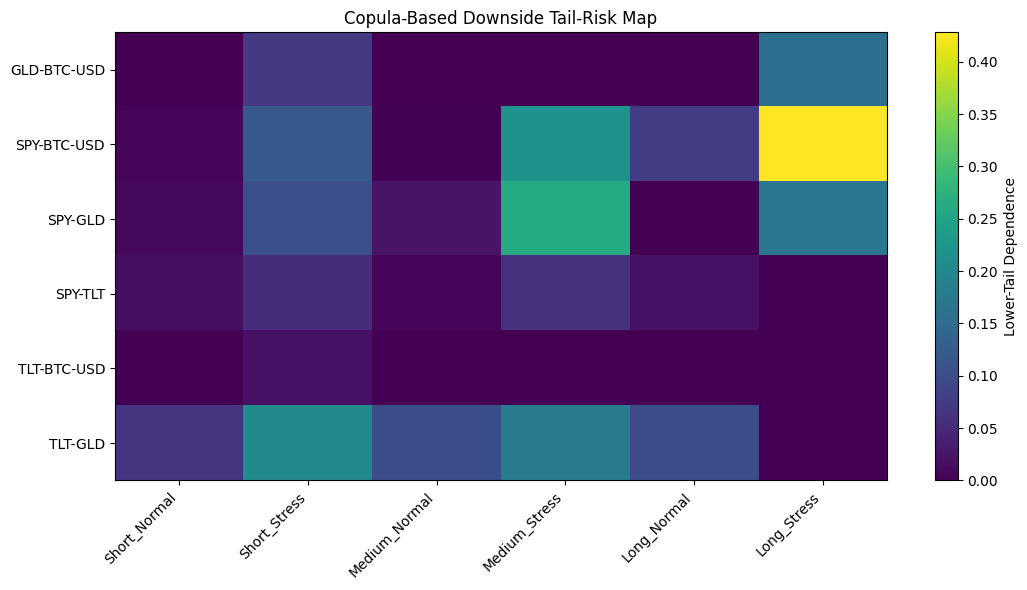

In [39]:
fig, ax = plt.subplots(
    figsize=(11, 6)
)

im = ax.imshow(
    lower_tail_matrix.values,
    aspect="auto"
)

ax.set_xticks(
    range(
        len(lower_tail_matrix.columns)
    )
)

ax.set_xticklabels(
    lower_tail_matrix.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(
        len(lower_tail_matrix.index)
    )
)

ax.set_yticklabels(
    lower_tail_matrix.index
)

plt.colorbar(
    im,
    ax=ax,
    label="Lower-Tail Dependence"
)

ax.set_title(
    "Copula-Based Downside Tail-Risk Map"
)

plt.tight_layout()
plt.show()

In [40]:
spy_btc_tail = (
    copula_tail_table[
        copula_tail_table["Pair"]
        ==
        "SPY-BTC-USD"
    ]
)

spy_btc_tail[
    [
        "Dataset",
        "Model",
        "Lambda_L"
    ]
]

,Dataset,Model,Lambda_L
1,Long_Normal,Student-t,0.075180
7,Long_Stress,Clayton,0.428123
13,Medium_Normal,Clayton,0.001685
19,Medium_Stress,Student-t,0.220620
25,Short_Normal,Student-t,0.005204
31,Short_Stress,Student-t,0.119819


In [41]:
all_copula_results.to_csv(
    "outputs/tables/all_copula_fits.csv",
    index=False
)

In [42]:
best_model_summary.to_csv(
    "outputs/tables/best_copula_models.csv",
    index=False
)

In [43]:
copula_tail_table.to_csv(
    "outputs/tables/copula_tail_dependence.csv",
    index=False
)

In [44]:
lower_tail_matrix.to_csv(
    "outputs/tables/copula_lower_tail_matrix.csv"
)

In [45]:
print(
    "Notebook 06 completed successfully."
)

print(
    "\nBest copula counts:"
)

print(
    best_model_summary[
        "Model"
    ].value_counts()
)

print(
    "\nLower-tail dependence:"
)

display(
    lower_tail_matrix.round(3)
)

Notebook 06 completed successfully.

Best copula counts:
Model
Student-t    22
Gaussian      8
Gumbel        4
Clayton       2
Name: count, dtype: int64

Lower-tail dependence:


Dataset,Short_Normal,Short_Stress,Medium_Normal,Medium_Stress,Long_Normal,Long_Stress
Pair,,,,,,
GLD-BTC-USD,0.000,0.071,0.000,0.000,0.000,0.157
SPY-BTC-USD,0.005,0.120,0.002,0.221,0.075,0.428
SPY-GLD,0.009,0.105,0.022,0.263,0.000,0.169
SPY-TLT,0.017,0.054,0.007,0.061,0.021,0.000
TLT-BTC-USD,0.000,0.020,0.000,0.000,0.000,0.000
TLT-GLD,0.066,0.204,0.103,0.176,0.102,0.000
